In [70]:
from pathlib import Path

import cmocean as cm
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pinner2026_jpo_code
import pinner2026_jpo_code.spectra

RAW_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "raw"
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"

# Data Handling

In [71]:
u_raw_mm = pd.read_csv(
    RAW_DATA_DIR / "moored_ADCP" / "AWI207_bottom_v.csv", skiprows=11, delimiter="\t"
)
u_raw_mm = u_raw_mm.drop(labels=["Unnamed: 5"], axis="columns")
v_raw_mm = pd.read_csv(
    RAW_DATA_DIR / "moored_ADCP" / "AWI207_bottom_u.csv", skiprows=11, delimiter="\t"
)
v_raw_mm = v_raw_mm.drop(labels=["Unnamed: 5"], axis="columns")

In [72]:
assert np.all(u_raw_mm.columns == v_raw_mm.columns)
assert u_raw_mm.shape == v_raw_mm.shape
assert u_raw_mm[["Ens", "HH", "MM", "SS"]].equals(v_raw_mm[["Ens", "HH", "MM", "SS"]])

In [73]:
v_raw_mm.head()

,Ens,HH,MM,SS,HH.1,1,2,3,4,5,...,31,32,33,34,35,36,37,38,39,40
0,1,15,9,47,16,-47.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,16,9,47,16,-1.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,17,9,47,16,9.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,18,9,47,16,3.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,19,9,47,16,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [74]:
v_raw_mm.info();

<class 'pandas.DataFrame'>
RangeIndex: 14761 entries, 0 to 14760
Data columns (total 45 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Ens     14761 non-null  int64  
 1   HH      14761 non-null  int64  
 2   MM      14761 non-null  int64  
 3   SS      14761 non-null  int64  
 4   HH.1    14761 non-null  int64  
 5   1       14760 non-null  float64
 6   2       14731 non-null  float64
 7   3       14731 non-null  float64
 8   4       14731 non-null  float64
 9   5       14731 non-null  float64
 10  6       14731 non-null  float64
 11  7       14731 non-null  float64
 12  8       14731 non-null  float64
 13  9       14731 non-null  float64
 14  10      14731 non-null  float64
 15  11      14731 non-null  float64
 16  12      14731 non-null  float64
 17  13      14731 non-null  float64
 18  14      14731 non-null  float64
 19  15      14730 non-null  float64
 20  16      14716 non-null  float64
 21  17      14690 non-null  float64
 22  18      1

- File Size 14.082.048 bytes
- BB/WH Ensemble Length 954 bytes
- System Frequency: 153.6 kHz
- 1st Bin 12,23 m, Bin Size 8,00 m
- No. Bins 40, Pings/Ens 42, Time/Ping 01:25.71
- First Ensemble 00000001 22/04/20 15:09:47.16
- Last  Ensemble 00014761 23/12/26 15:09:47.16 Extra Data in File
- Average Ensemble Interval 00:10:20,69
- distance from ground: 10 m

In [75]:
DISTANCE_FROM_GROUND_METERS = 10.0
DISTANCE_FROM_ADCP = 12.23
VERTICAL_BIN_SIZE = 8.0
FIRST_DAY = pd.to_datetime("22/04/20", yearfirst=True)
FIRST_ENSEMBLE = pd.to_datetime("22/04/20 15:09:47.16", yearfirst=True)
LAST_ENSEMBLE = pd.to_datetime("23/12/26 15:09:47.16", yearfirst=True)
ENSEMBLE_COUNT = u_raw_mm.shape[0]
print(FIRST_ENSEMBLE)
print(LAST_ENSEMBLE)

2022-04-20 15:09:47.160000
2023-12-26 15:09:47.160000


In [76]:
# Get the start time from the first row
start_time = pd.Timedelta(
    hours=u_raw_mm["HH"].iloc[0], minutes=u_raw_mm["MM"].iloc[0], seconds=u_raw_mm["SS"].iloc[0]
)

# Compute each row's timedelta from midnight of the start date
row_times = (
    pd.to_timedelta(u_raw_mm["HH"], unit="h")
    + pd.to_timedelta(u_raw_mm["MM"], unit="m")
    + pd.to_timedelta(u_raw_mm["SS"], unit="s")
)

# Find where the time rolls over (i.e. row time < previous row time)
# and compute a day offset that increments at each rollover
day_offsets = (row_times < row_times.shift(1, fill_value=row_times.iloc[0])).cumsum()

# Combine: start_date + day_offset + row_time
timestamps = FIRST_DAY + pd.to_timedelta(day_offsets, unit="D") + row_times
assert LAST_ENSEMBLE - timestamps.iloc[-1] < pd.to_timedelta(1, unit="s")

u_raw_mm.index = timestamps
v_raw_mm.index = timestamps
u_raw_mm = u_raw_mm.drop(labels=["Ens", "HH", "MM", "SS", "HH.1"], axis="columns")
v_raw_mm = v_raw_mm.drop(labels=["Ens", "HH", "MM", "SS", "HH.1"], axis="columns")

In [77]:
u_raw_mm.columns = (
    DISTANCE_FROM_GROUND_METERS
    + DISTANCE_FROM_ADCP
    + u_raw_mm.columns.astype(int) * VERTICAL_BIN_SIZE
).round(2)
v_raw_mm.columns = (
    DISTANCE_FROM_GROUND_METERS
    + DISTANCE_FROM_ADCP
    + v_raw_mm.columns.astype(int) * VERTICAL_BIN_SIZE
).round(2)

In [78]:
# conversion from mm/s to m/s
u_raw_m = u_raw_mm / 100
v_raw_m = v_raw_mm / 100

In [79]:
u_raw_m.head()

,30.23,38.23,46.23,54.23,62.23,70.23,78.23,86.23,94.23,102.23,...,270.23,278.23,286.23,294.23,302.23,310.23,318.23,326.23,334.23,342.23
2022-04-20 15:09:47,0.31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-20 16:09:47,0.03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-20 17:09:47,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-20 18:09:47,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-04-20 19:09:47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Data Cleaning

Text(0.5, 0, 'v / (m/s)')

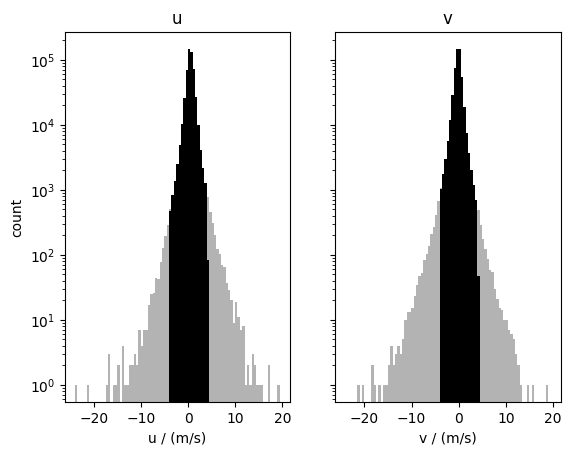

In [80]:
fig, ax = plt.subplots(ncols=2, sharex=True, sharey=True)
binwidth = 0.5
ubins = np.arange(u_raw_m.min(axis=None), u_raw_m.max(axis=None) + binwidth, binwidth)
vbins = np.arange(u_raw_m.min(axis=None), u_raw_m.max(axis=None) + binwidth, binwidth)
ax[0].hist(u_raw_m.to_numpy().flatten(), bins=ubins, log=True, color="0.7")
ax[1].hist(v_raw_m.to_numpy().flatten(), bins=vbins, log=True, color="0.7")

ut = u_raw_m.copy()
vt = v_raw_m.copy()

MAX_REASONABLE_VELOCITY = 4  # m/s
# remove everything faster than MAX_REASONABLE_VELOCITY
ut[u_raw_m.abs() > MAX_REASONABLE_VELOCITY] = np.nan
vt[v_raw_m.abs() > MAX_REASONABLE_VELOCITY] = np.nan

ax[0].hist(ut.to_numpy().flatten(), bins=ubins, log=True, color="k")
ax[1].hist(vt.to_numpy().flatten(), bins=vbins, log=True, color="k")

ax[0].set_title("u")
ax[1].set_title("v")

ax[0].set_ylabel("count")

ax[0].set_xlabel("u / (m/s)")
ax[1].set_xlabel("v / (m/s)")

# for axis in ax:
#     axis.axvline(MAX_REASONABLE_VELOCITY, color="tab:red", ls = "--")
#     axis.axvline(-MAX_REASONABLE_VELOCITY, color="tab:red", ls = "--")

In [81]:
# vertical smoothing
u_smoothed = ut.T.rolling(window=3, center=True).mean().T
v_smoothed = vt.T.rolling(window=3, center=True).mean().T

In [82]:
u_smoothed.columns

Index([ 30.23,  38.23,  46.23,  54.23,  62.23,  70.23,  78.23,  86.23,  94.23,
       102.23, 110.23, 118.23, 126.23, 134.23, 142.23, 150.23, 158.23, 166.23,
       174.23, 182.23, 190.23, 198.23, 206.23, 214.23, 222.23, 230.23, 238.23,
       246.23, 254.23, 262.23, 270.23, 278.23, 286.23, 294.23, 302.23, 310.23,
       318.23, 326.23, 334.23, 342.23],
      dtype='float64')

In [83]:
u_smoothed = u_smoothed.loc[:, 30.23:190.23]
v_smoothed = v_smoothed.loc[:, 30.23:190.23]

In [84]:
u_smoothed.to_csv(INTERIM_DATA_DIR / "AWI207_bottom_u.csv")
v_smoothed.to_csv(INTERIM_DATA_DIR / "AWI207_bottom_v.csv")

In [86]:
# fs = 1 / (1 * 60 * 60)  # sampling period of 1 hour
# cut = 1 / (13.8 * 60 * 60)  # tail end of the continuum
# # cut = 1 / (7 * 60 * 60)  # tail end of the continuum
# order = 40

# sos = signal.butter(N=order, Wn=cut, btype="highpass", fs=fs, output="sos")
# # use filtfilt with 2 filtering passes to prevent an artificial phase shift
# superinertial_u = pd.Series(index=u_smoothed.index, data=signal.sosfiltfilt(sos, u_smoothed.values))
# superinertial_v = pd.Series(index=u_smoothed.index, data=signal.sosfiltfilt(sos, u_smoothed.values))

# Velocity

In [87]:
u = pd.read_csv(INTERIM_DATA_DIR / "AWI207_bottom_u.csv", parse_dates=True, index_col=0)
u.columns = u.columns.astype(float)
v = pd.read_csv(INTERIM_DATA_DIR / "AWI207_bottom_v.csv", parse_dates=True, index_col=0)
v.columns = v.columns.astype(float)

In [88]:
u.columns

Index([ 30.23,  38.23,  46.23,  54.23,  62.23,  70.23,  78.23,  86.23,  94.23,
       102.23, 110.23, 118.23, 126.23, 134.23, 142.23, 150.23, 158.23, 166.23,
       174.23, 182.23, 190.23],
      dtype='float64')

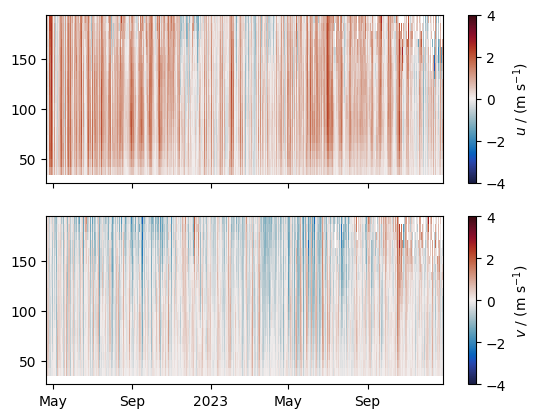

In [89]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True)

max_plot_velocity = MAX_REASONABLE_VELOCITY
# max_plot_velocity= 2

im0 = ax[0].pcolormesh(
    u.index,
    u.columns,
    u.to_numpy().T,
    norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-max_plot_velocity, vmax=max_plot_velocity),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v.index,
    v.columns,
    v.to_numpy().T,
    norm=mcolors.TwoSlopeNorm(vcenter=0, vmin=-max_plot_velocity, vmax=max_plot_velocity),
    cmap=cm.cm.balance,
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

for axis in ax:
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

In [90]:
# v = pd.DataFrame(0, index=v.index, columns=v.columns)

In [91]:
# speed = (u.rolling("3h").mean() + (1j * v)).abs()
speed = (u + (1j * v)).abs()

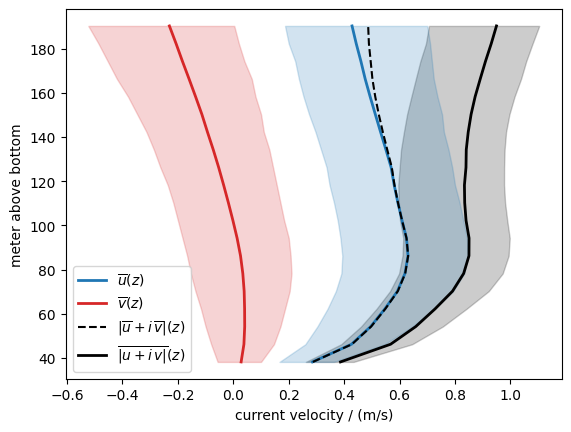

In [92]:
fig, ax = plt.subplots(1)

quant = 0.66

ax.fill_betweenx(
    speed.columns,
    speed.quantile(1 - quant, axis="index"),
    speed.quantile(quant, axis="index"),
    alpha=0.2,
    color="k",
)

ax.plot(u.mean(axis="index"), u.columns, label="$\\overline{u}(z)$", color="tab:blue", lw=2)
ax.fill_betweenx(
    u.columns,
    u.quantile(1 - quant, axis="index"),
    u.quantile(quant, axis="index"),
    alpha=0.2,
    color="tab:blue",
)

ax.plot(v.mean(axis="index"), v.columns, label="$\\overline{v}(z)$", color="tab:red", lw=2)
ax.fill_betweenx(
    v.columns,
    v.quantile(1 - quant, axis="index"),
    v.quantile(quant, axis="index"),
    alpha=0.2,
    color="tab:red",
)

ax.plot(
    np.abs(u.mean(axis="index") + 1j * v.mean(axis="index")),
    u.columns,
    label="$|\\overline{u} + i\\,\\overline{v}|(z)$",
    color="k",
    ls="--",
)
ax.plot(
    speed.mean(axis="index"), speed.columns, label="$\\overline{|u + i\\,v|}(z)$", color="k", lw=2
)

ax.set_ylabel("meter above bottom")
ax.set_xlabel("current velocity / (m/s)")
ax.legend();

# Vertical Shear

In [93]:
u_shear = pd.DataFrame(
    np.gradient(u.to_numpy(), u.columns, axis=1),
    index=u.index,
    columns=u.columns,
)

v_shear = pd.DataFrame(
    np.gradient(v.to_numpy(), v.columns, axis=1),
    index=v.index,
    columns=v.columns,
)

"""
u_shear = pd.DataFrame(
    np.gradient(u.rolling("3h").mean().to_numpy(), u.columns, axis=1), index=u.index, columns=u.columns
)
v_shear = pd.DataFrame(
    np.gradient(v.rolling("3h").mean().to_numpy(), u.columns, axis=1), index=u.index, columns=u.columns
)
"""

Su = u_shear**2
Sv = v_shear**2

u_shear_control = u.diff(axis=1) / VERTICAL_BIN_SIZE
v_shear_control = v.diff(axis=1) / VERTICAL_BIN_SIZE
Su_control = u_shear_control**2
Sv_control = v_shear_control**2

In [94]:
# plt.hist((Sv- Sv_control).to_numpy().flatten(), log=True, bins=20)

Text(0.5, 0, '$S_v^2$ / (s$^{-2}$)')

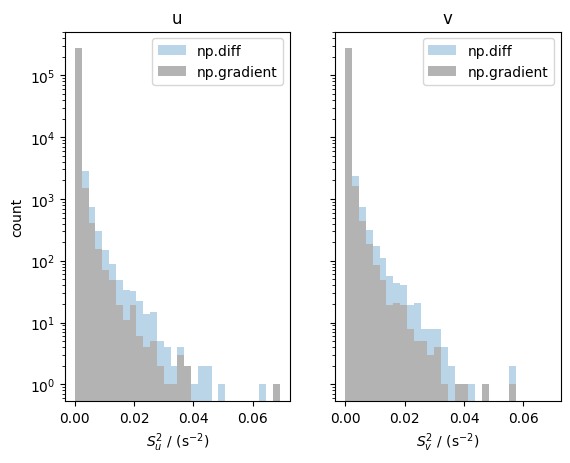

In [95]:
fig, ax = plt.subplots(ncols=2, sharex=True, sharey=True)
binwidth = (Su.max(axis=None) - Su.min(axis=None)) / 30
ubins = np.arange(Su.min(axis=None), Su.max(axis=None) + binwidth, binwidth)
vbins = np.arange(Sv.min(axis=None), Sv.max(axis=None) + binwidth, binwidth)

ax[0].hist(
    Su_control.to_numpy().flatten(),
    bins=ubins,
    log=True,
    color="tab:blue",
    alpha=0.3,
    label="np.diff",
)
ax[1].hist(
    Sv_control.to_numpy().flatten(),
    bins=vbins,
    log=True,
    color="tab:blue",
    alpha=0.3,
    label="np.diff",
)

ax[0].hist(Su.to_numpy().flatten(), bins=ubins, log=True, color="0.7", label="np.gradient")
ax[1].hist(Sv.to_numpy().flatten(), bins=vbins, log=True, color="0.7", label="np.gradient")

ax[0].set_title("u")
ax[1].set_title("v")
ax[0].legend()
ax[1].legend()
ax[0].set_ylabel("count")

ax[0].set_xlabel("$S_u^2$ / (s$^{-2}$)")
ax[1].set_xlabel("$S_v^2$ / (s$^{-2}$)")

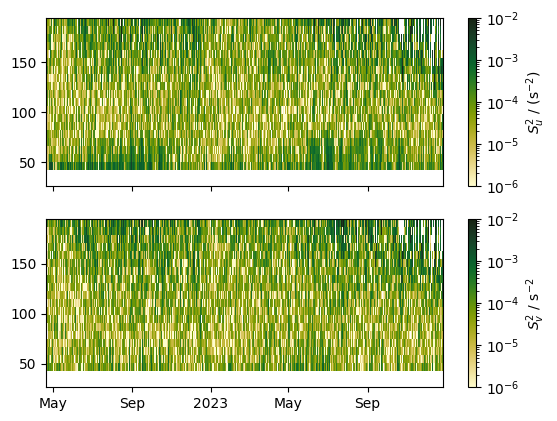

In [96]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True)

# max_plot_shear =  2* MAX_REASONABLE_VELOCITY / VERTICAL_BIN_SIZE
# max_plot_shear_squared = 1 * 1e-3

norm = mcolors.LogNorm(vmin=1e-6, vmax=1e-2)
# norm = mcolors.PowerNorm(gamma=1) #, vmin=0, vmax=1e-3) #gamma = 1 means linear

im0 = ax[0].pcolormesh(Su.index, Su.columns, Su.to_numpy().T, norm=norm, cmap=cm.cm.speed)
im1 = ax[1].pcolormesh(Sv.index, Sv.columns, Sv.to_numpy().T, norm=norm, cmap=cm.cm.speed)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$S_u^2$ / (s$^{-2}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$S_v^2$ / s$^{-2}$")

for axis in ax:
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

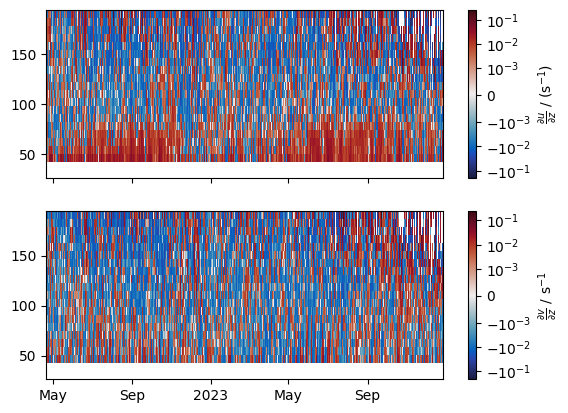

In [97]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True)

linthresh = 1e-3

im0 = ax[0].pcolormesh(
    u_shear.index,
    u_shear.columns,
    u_shear.to_numpy().T,
    norm=mcolors.SymLogNorm(linthresh),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_shear.index,
    v_shear.columns,
    v_shear.to_numpy().T,
    norm=mcolors.SymLogNorm(linthresh),
    cmap=cm.cm.balance,
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$\\frac{\\partial u}{\\partial z}$ / (s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$\\frac{\\partial v}{\\partial z}$ / s$^{-1}$")

for axis in ax:
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

In [98]:
u_shear.to_csv(INTERIM_DATA_DIR / "AWI207_bottom_u_shear.csv")
v_shear.to_csv(INTERIM_DATA_DIR / "AWI207_bottom_v_shear.csv")